NEU-DET Analytics-Assisted CNN

This notebook tests whether DCT and morphology-derived channels improve CNN classification.

Multi-Channel Preprocessing

The model receives grayscale intensity, normalized high-frequency DCT detail, and a morphology response as three input channels.

In [2]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

PROJECT = Path.cwd()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent
ROOT = PROJECT / 'dataset' / 'NEU-DET'
OUTPUTS = PROJECT / 'outputs' / 'neu_analytics_cnn'
OUTPUTS.mkdir(parents=True, exist_ok=True)
CLASSES = ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
device = 'cuda' if torch.cuda.is_available() else 'cpu'

Analytics Channel Construction

DCT and morphology are used as additional image representations, not as replacement labels.

In [3]:
def channels(file):
    gray = cv2.imread(str(file), cv2.IMREAD_GRAYSCALE)
    gray = cv2.resize(gray, (200, 200)).astype(np.float32) / 255
    dct = cv2.dct(gray)
    high = dct.copy()
    high[:32, :32] = 0
    high = cv2.normalize(np.abs(high), None, 0, 1, cv2.NORM_MINMAX)
    _, binary = cv2.threshold((gray * 255).astype(np.uint8), 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    morphology = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
    morphology = cv2.morphologyEx(morphology, cv2.MORPH_CLOSE, kernel).astype(np.float32) / 255
    return np.stack([gray, high, morphology])

Dataset and Model

A small CNN receives the three analytics channels and predicts the six defect classes.

In [4]:
class ChannelDataset(Dataset):
    def __init__(self, split):
        self.items = [(file, CLASSES.index(category)) for category in CLASSES for file in sorted((ROOT / split / 'images' / category).glob('*'))]
    def __len__(self):
        return len(self.items)
    def __getitem__(self, index):
        file, label = self.items[index]
        return torch.tensor(channels(file), dtype=torch.float32), label

train_loader = DataLoader(ChannelDataset('train'), batch_size=32, shuffle=True)
validation_loader = DataLoader(ChannelDataset('validation'), batch_size=32)

class AnalyticsCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(32 * 50 * 50, 128), nn.ReLU(), nn.Dropout(.3), nn.Linear(128, 6))
    def forward(self, x):
        return self.classifier(self.features(x))

model = AnalyticsCNN().to(device)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

Training and Evaluation

The same training schedule and validation split are used for comparison with the grayscale CNN.

{'epoch': 1, 'loss': 1.3634094754854837, 'validation_accuracy': np.float64(0.7194444444444444)}
{'epoch': 2, 'loss': 0.5796755615207884, 'validation_accuracy': np.float64(0.8555555555555555)}
{'epoch': 3, 'loss': 0.26673883580499225, 'validation_accuracy': np.float64(0.9305555555555556)}
{'epoch': 4, 'loss': 0.15975783608025976, 'validation_accuracy': np.float64(0.9166666666666666)}
{'epoch': 5, 'loss': 0.08211414385586976, 'validation_accuracy': np.float64(0.9416666666666667)}
{'epoch': 6, 'loss': 0.046319029418130715, 'validation_accuracy': np.float64(0.9361111111111111)}
{'epoch': 7, 'loss': 0.06067632780306869, 'validation_accuracy': np.float64(0.9361111111111111)}
{'epoch': 8, 'loss': 0.06317256344482303, 'validation_accuracy': np.float64(0.9527777777777777)}
{'epoch': 9, 'loss': 0.03663370996299717, 'validation_accuracy': np.float64(0.9694444444444444)}
{'epoch': 10, 'loss': 0.01904332735705086, 'validation_accuracy': np.float64(0.9833333333333333)}
                 precision    

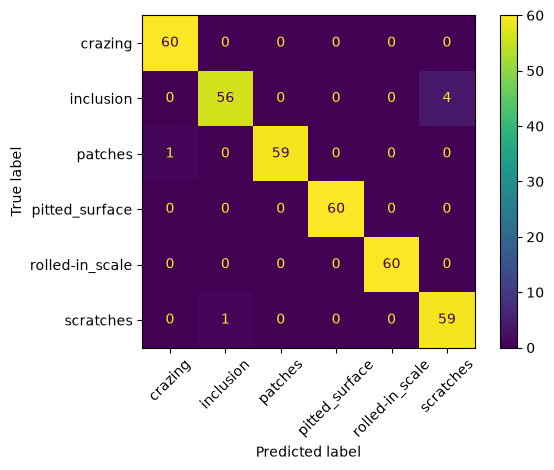

In [5]:
history = []
for epoch in range(10):
    model.train()
    total_loss = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = loss_function(model(images), labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    model.eval()
    actual, predicted = [], []
    with torch.no_grad():
        for images, labels in validation_loader:
            actual.extend(labels.numpy())
            predicted.extend(model(images.to(device)).argmax(1).cpu().numpy())
    accuracy = np.mean(np.array(actual) == np.array(predicted))
    history.append({'epoch': epoch + 1, 'loss': total_loss / len(train_loader), 'validation_accuracy': accuracy})
    print(history[-1])

history = pd.DataFrame(history)
print(classification_report(actual, predicted, target_names=CLASSES))
ConfusionMatrixDisplay.from_predictions(actual, predicted, display_labels=CLASSES, xticks_rotation=45)
plt.tight_layout(); plt.savefig(OUTPUTS / 'analytics_cnn_confusion_matrix.png', bbox_inches='tight'); plt.show()
history.to_csv(OUTPUTS / 'analytics_cnn_history.csv', index=False)
torch.save(model.state_dict(), OUTPUTS / 'analytics_cnn.pt')

Findings

The analytics-assisted result is compared with the grayscale CNN and Random Forest baselines.

In [6]:
print('The grayscale channel preserves the original appearance.')
print('The DCT channel emphasizes frequency detail.')
print('The morphology channel provides a cleaned structural response.')
print('Compare validation accuracy and class-wise errors across all three models.')

The grayscale channel preserves the original appearance.
The DCT channel emphasizes frequency detail.
The morphology channel provides a cleaned structural response.
Compare validation accuracy and class-wise errors across all three models.
